## Feature processing for timeseries analysis

- This notebook is focused on analyzing the mean behavior of the library, over time

- It outputs a timeseries dataframe and a steady state dataframe

- Most steady state analysis is in another notebook, however

In [1]:
import trenchripper as tr

import numpy as np
import pandas as pd
import scipy as sp
import sklearn as skl
import dask.dataframe as dd

import scipy.stats
import dask
import warnings
import random

from dask.distributed import wait
from statsmodels.nonparametric import kernel_regression

from matplotlib import pyplot as plt

dask_sample_seed = 42
random.seed(42)
np.random.seed(42)

dask_wd = "/home/lag36/scratch/lag36/dask"
warnings.filterwarnings(action='once',category=UserWarning)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [40]:
def get_l_norm(x,right_tail_only=False):
    if right_tail_only:
        x_median = np.nanmedian(x)
        x_vals = x[x>x_median]
    else:
        x_vals = x
    l_norm = sp.stats.yeojohnson_normmax(x_vals)
    return l_norm

def apply_transform(final_output_df_filtered,yeo_subsample = 1,dask_sample_seed=dask_sample_seed,early_time_cutoff=28800,steady_state_time_cutoff=64800,clipping_range=(-4,4),\
                    params_to_transform = ['Division: major_axis_length'], transform_list=["YJ-Right"], time_label="time (s)",trenchid_label="Multi-Experiment Phenotype Trenchid",\
                   gmm_scaling=True):
    
    subsample_df = final_output_df_filtered.sample(frac=yeo_subsample, random_state = dask_sample_seed).persist()
    subsample_df_final = subsample_df[subsample_df[time_label]>=steady_state_time_cutoff]
    subsample_df_init = subsample_df[subsample_df[time_label]<early_time_cutoff]
    for i,param in enumerate(params_to_transform):
        print(param)
        transform = transform_list[i]
        param_vals_final = subsample_df_final[param].astype(float).compute().tolist()
        param_vals_final = np.array(param_vals_final)
        param_vals_final = param_vals_final[~np.isnan(param_vals_final)]

        param_vals_init = subsample_df_init[param].astype(float).compute().tolist()
        param_vals_init = np.array(param_vals_init)
        param_vals_init = param_vals_init[~np.isnan(param_vals_init)]

        ### extract high variance GMM component
        # Fit a Gaussian Mixture Model with two components
        X = param_vals_final[:,np.newaxis]
        if gmm_scaling:
            gmm = skl.mixture.GaussianMixture(n_components=2, random_state=dask_sample_seed)
            gmm.fit(X)
            
            covars = gmm.covariances_[:,0,0]
            max_var_component = np.argmax(covars)
                   
            probs = gmm.predict_proba(X)
            weights = probs[:, max_var_component]
            ### generate a weighted sample from this component
            weighted_sample = np.random.choice(X.flatten(), size=len(X), p=weights/weights.sum())
        else:
            weighted_sample = X.flatten()

        if transform == "YJ" or transform == "YJ-Right":
            if transform == "YJ":
                l_norm = get_l_norm(weighted_sample,right_tail_only=False)
            elif transform == "YJ-Right":
                l_norm = get_l_norm(weighted_sample,right_tail_only=True)
            final_output_df_filtered[param + ": Transformed"] = final_output_df_filtered[param].apply(lambda x: sp.stats.yeojohnson(x,lmbda = l_norm), meta=(param + ": Transformed",float)).persist()
            transformed_weighted_sample = sp.stats.yeojohnson(weighted_sample,lmbda=l_norm)
            transformed_initial_values = sp.stats.yeojohnson(param_vals_init,lmbda=l_norm)
        elif transform == "None":
            final_output_df_filtered[param + ": Transformed"] = final_output_df_filtered[param]
            transformed_weighted_sample = weighted_sample
            transformed_initial_values = param_vals_init

        weighted_sigma = np.std(transformed_weighted_sample)
        median_val = np.median(transformed_initial_values)
        feature_scores = (1.35*((final_output_df_filtered[param + ": Transformed"] - median_val)/weighted_sigma))
        feature_scores = np.clip(feature_scores,clipping_range[0],clipping_range[1])
        final_output_df_filtered[param + ": Transformed: z score"] = feature_scores.persist()
        
    final_output_df_filtered = final_output_df_filtered.reset_index().set_index(trenchid_label,drop=True,sorted=True)
    return final_output_df_filtered

def timeseries_kernel_reg(df, y_label, min_tpt, max_tpt, kernel_bins, kernel_bandwidth, nan_filter, time_label="Final time (s)", trenchid_label="Multi-Experiment Phenotype Trenchid"):
    def kernel_reg(x_arr,y_arr,nan_filter,start=min_tpt,end=max_tpt,kernel_bins=kernel_bins,kernel_bandwidth=kernel_bandwidth):
        intervals = np.linspace(start, end, num=kernel_bins, dtype=float)
        try:
            if nan_filter:
                nan_mask = ~np.isnan(y_arr)
                y_arr = y_arr[nan_mask]
                x_arr = x_arr[nan_mask]
            if len(x_arr)>0:
                w = kernel_regression.KernelReg(y_arr,x_arr,"c",reg_type="lc",bw=np.array([kernel_bandwidth]),ckertype="gaussian").fit(intervals)[0]
                reg_x, reg_y = (intervals, w)
            else:
                reg_x, reg_y = (intervals, [np.NaN for idx in range(len(intervals))])
        except:
            reg_x, reg_y = (intervals, [np.NaN for idx in range(len(intervals))])
        return reg_x, reg_y
    kernel_result = df.groupby(trenchid_label).apply(lambda x: list(kernel_reg(x[time_label].values,x[y_label].values,nan_filter)[1]),meta=(y_label, object),)
    return kernel_result


def get_all_kernel_regs(df, y_label_list, nan_filter_list=[], min_tpt = 0, max_tpt = 36000, kernel_bins=20, kernel_bandwidth = 7200, time_label="Cell Cycle", trenchid_label="Multi-Experiment Phenotype Trenchid"):
    out_df = []
    for y_label in y_label_list:
        sub_df = df[[y_label,time_label]]
        
        if y_label in nan_filter_list:
            kernel_result = timeseries_kernel_reg(sub_df, y_label, min_tpt, max_tpt, kernel_bins, kernel_bandwidth, True, time_label=time_label, trenchid_label=trenchid_label)
        else:
            kernel_result = timeseries_kernel_reg(sub_df, y_label, min_tpt, max_tpt, kernel_bins, kernel_bandwidth, False, time_label=time_label, trenchid_label=trenchid_label)
        kernel_result = kernel_result
        kernel_result.name = "Kernel Trace: " + y_label
        out_df.append(kernel_result)
    out_df = dd.concat(out_df, axis=1)
    return out_df

def explode_kernel_trace(series_x):
    output = series_x.apply(lambda x: eval(x)).explode().to_frame()
    return output

def agg_sem(x,vector):
    arr = np.array([eval(item) for item in x[vector].tolist()])
    sem_arr = sp.stats.sem(arr, axis=0, nan_policy='propagate')
    sem_arr[np.isnan(sem_arr)] = -1
    output = sem_arr.tolist()
    return output

def unpack_sem(x):
    sem_arr = np.array(eval(x))
    sem_arr[sem_arr==-1] = np.NaN
    return sem_arr

## need a jankknife mean function
def agg_sem_jackknife(x):
    sem_arr = sp.stats.sem(np.array(x.values.tolist()),axis=0,nan_policy='propagate')
    sem_arr[np.isnan(sem_arr)] = -1
    output = sem_arr.tolist()
    return output

def unpack_sem_jackknife(x):
    sem_arr = np.array(eval(x))
    sem_arr[sem_arr==-1] = np.NaN
    return sem_arr

def get_jackknife_mean(jackknife_df_temp_path,jackknife_i,jackknife_ttl):
    jackknife_df = pd.read_pickle(jackknife_df_temp_path)
    indices_to_drop = jackknife_df.index[jackknife_i::jackknife_ttl]
    jackknife_df = jackknife_df.drop(indices_to_drop)
    single_jackknife = jackknife_df.groupby("opLAG1_id")["Feature Vector"].apply(lambda x: np.mean(np.array(x.values.tolist()),axis=0).tolist())
    single_jackknife = single_jackknife.to_frame()
    jackknife_sem = jackknife_df.groupby("opLAG1_id")["Feature Vector"].apply(lambda x: agg_sem_jackknife(x))    
    single_jackknife["SEM: Feature Vector"] = jackknife_sem
    single_jackknife["Jackknife"] = jackknife_i
    return single_jackknife

def get_mean_var_and_cv(df,final_columns,columns_to_apply_aggregation,sgrna_key='opLAG1_id'):
    sgrna_sorted = df.reset_index(drop=True).set_index(sgrna_key).persist()
    sgrna_groupby = sgrna_sorted.groupby(sgrna_key)
    mean_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: np.mean(x,axis=0)).compute()
    std_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: np.std(x,axis=0,ddof=1)).compute()
    cv_df = std_df/mean_df
    var_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: np.var(x,axis=0)).compute()
    count_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: x.count()).compute()
    sem_df = std_df/np.sqrt(count_df)
        
    mean_df = mean_df.rename(columns={key: "Mean: " + key for key in mean_df.columns.tolist()})
    var_df = var_df.rename(columns={key: "Variance: " + key for key in var_df.columns.tolist()})
    cv_df = cv_df.rename(columns={key: "CV: " + key for key in cv_df.columns.tolist()})
    sem_df = sem_df.rename(columns={key: "SEM: " + key for key in sem_df.columns.tolist()})
    
    output_df = sgrna_groupby.first().compute()
    output_df = output_df[final_columns]
    output_df = output_df.join(mean_df)
    output_df = output_df.join(var_df)
    output_df = output_df.join(cv_df)
    output_df = output_df.join(sem_df)
    
    return output_df

### Initial Data Processing (Mean Timeseries)

#### Start Dask

In [ ]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="04:00:00",
#     local=False,
#     n_workers=300,
#     n_workers_min=200,
#     memory="16GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

dask_controller = tr.trcluster.dask_controller(
    walltime="04:00:00",
    local=False,
    n_workers=100,
    n_workers_min=100,
    memory="16GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

230m
04:00:00


### Kernel regression on each trench

In [ ]:
partition_size = "500MB"

HEADPATH = '/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/'
PREFIX = '2025-06-03_lLAG8_'
MIN_TIMEPOINT_SECONDS = 0
MAX_TIMEPOINT_SECONDS = 43000

cell_cycle_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/', engine="pyarrow",calculate_divisions=True)
timepoints_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Observations_Merged/', engine="pyarrow",calculate_divisions=True)
growth_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Growth_Observations_Merged/', engine="pyarrow",calculate_divisions=True)

cell_cycle_df = cell_cycle_df.repartition(partition_size = partition_size)
timepoints_df = timepoints_df.repartition(partition_size = partition_size)
growth_df = growth_df.repartition(partition_size = partition_size)

In [10]:
timepoints_df.columns

Index(['Global CellID-Cell Cycle timepoints', 'phenotype trenchid',
       'Global CellID', 'Cell Cycle timepoints', 'Observation time (s)',
       'area', 'Length', 'Width', 'Surface Area', 'Volume',
       'mCherry mean_intensity', 'Experiment #',
       'Multi-Experiment Global CellID', 'Length: Probability',
       'Width: Probability', 'mCherry mean_intensity: Probability'],
      dtype='object')

In [11]:
print(cell_cycle_df['time (s)'].min().compute(), cell_cycle_df['time (s)'].max().compute())
print(timepoints_df['Observation time (s)'].min().compute(), timepoints_df['Observation time (s)'].max().compute())
print(growth_df['Measurement time (s)'].min().compute(), growth_df['Measurement time (s)'].max().compute())

610.8834032597551 42459.46194775963
1.9573485798828187 43658.88953899956
607.8982938798266 43059.43605325969


In [16]:
43800 / (10*60)

73.0

In [17]:
cell_cycle_params = ['Birth: Length', 'Division: Length',
   'Delta: Length', 'Birth: Width',
   'Division: Width', 'Delta: Width',
   'Birth: Volume', 'Division: Volume', 'Delta: Volume',
   'Final timepoints', 'Delta Timepoints', 'Final time (s)',
   'Delta time (s)','Septum Displacement','Septum Displacement Length Normalized']
timepoints_params = ['area','Length', 'Width', 'Volume','mCherry mean_intensity']
growth_params = ['Instantaneous Growth Rate: Volume', 'Instantaneous Growth Rate: Length']
all_traced_params = cell_cycle_params + timepoints_params + growth_params
all_traced_params = ["Kernel Trace: " + item for item in all_traced_params]

bandwidth_hours = 2
kernel_bins = 20

cell_cycle_kernel_df = get_all_kernel_regs(
    cell_cycle_df,
    cell_cycle_params,
    min_tpt = 0,
    max_tpt = 43800,#36000,
    kernel_bins = kernel_bins,
    kernel_bandwidth = bandwidth_hours*3600,
    time_label="Mid-Cycle time (s)",
    trenchid_label="Multi-Experiment Phenotype Trenchid")
cell_cycle_kernel_df = cell_cycle_kernel_df.persist()
wait(cell_cycle_kernel_df);

timepoints_kernel_df = get_all_kernel_regs(
    timepoints_df,
    timepoints_params,
    min_tpt = 0,
    max_tpt = 43800,#36000,
    kernel_bins = kernel_bins,
    kernel_bandwidth = bandwidth_hours*3600,
    time_label="Observation time (s)",
    trenchid_label="Multi-Experiment Phenotype Trenchid")
timepoints_kernel_df = timepoints_kernel_df.persist()
wait(timepoints_kernel_df);

growth_kernel_df = get_all_kernel_regs(
    growth_df,
    growth_params,
    min_tpt = 0,
    max_tpt = 43800,#36000,
    kernel_bins = kernel_bins,
    kernel_bandwidth = bandwidth_hours*3600,
    time_label="Measurement time (s)",
    trenchid_label="Multi-Experiment Phenotype Trenchid")
growth_kernel_df = growth_kernel_df.persist()
wait(growth_kernel_df);

In [18]:
## nan filter
cell_cycle_kernel_nan_filter = cell_cycle_kernel_df.apply(lambda x: \
                            ~np.any(["nan" in item for item in x.tolist()]), axis=1, meta=bool).persist()
cell_cycle_kernel_df_filtered = cell_cycle_kernel_df[cell_cycle_kernel_nan_filter]
filtered_trenchid_indices = cell_cycle_kernel_df_filtered.index.unique().compute()
timepoints_kernel_df_filtered = timepoints_kernel_df.loc[filtered_trenchid_indices]
growth_kernel_df_filtered = growth_kernel_df.loc[filtered_trenchid_indices]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(


#### Merge Timeseries dfs

In [19]:
trenchid_label="Multi-Experiment Phenotype Trenchid"

cell_cycle_single_trenchid = cell_cycle_df.groupby(trenchid_label).first()
timepoints_single_trenchid = timepoints_df.groupby(trenchid_label).first()
growth_out_single_trenchid = growth_df.groupby(trenchid_label).first()

cell_cycle_out = cell_cycle_kernel_df_filtered.join(cell_cycle_single_trenchid)
timepoints_out = timepoints_kernel_df_filtered.join(timepoints_single_trenchid)
growth_out = growth_kernel_df_filtered.join(growth_out_single_trenchid)

traced_col_names = [col_name for col_name in cell_cycle_out.columns.tolist() if col_name in all_traced_params]
cell_cycle_out = cell_cycle_out[['Global CellID', 'File Parquet Index', 'fov', 'row', 'trench',
       'initial timepoints', 'File Index', 'File Trench Index', 'CellID',
       'Trench Score', 'Mother CellID', 'Daughter CellID 1',
       'Daughter CellID 2', 'Sister CellID', 'Centroid X', 'Centroid Y',
       'Kymograph File Parquet Index', 'Kymograph FOV Parquet Index',
       'FOV Parquet Index', 'Experiment #', 'phenotype trenchid'] + traced_col_names]

traced_col_names = [col_name for col_name in timepoints_out.columns.tolist() if col_name in all_traced_params]
timepoints_out = timepoints_out[traced_col_names]

traced_col_names = [col_name for col_name in growth_out.columns.tolist() if col_name in all_traced_params]
growth_out = growth_out[traced_col_names]

timeseries_merged_dd = dd.concat([cell_cycle_out,timepoints_out,growth_out], axis=1)
timeseries_merged_dd = timeseries_merged_dd.repartition(partition_size=partition_size).persist()
wait(timeseries_merged_dd);

#### Export Kernel Regression Dataframe

In [20]:
HEADPATH+"/2025-08-11_lLAG8_Kernel_Regression_df"

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed//2025-08-11_lLAG8_Kernel_Regression_df'

In [21]:
kernel_trace_columns = [column_name for column_name in timeseries_merged_dd.columns if "Kernel Trace" in column_name]
explode_series_list = []
for column_name in kernel_trace_columns:
    empty_df_ex = pd.DataFrame(data=[],columns=["Multi-Experiment Phenotype Trenchid",column_name]).astype({"Multi-Experiment Phenotype Trenchid":int,\
                                                column_name:float}).set_index("Multi-Experiment Phenotype Trenchid")
    working_exploded_column = timeseries_merged_dd[column_name].map_partitions(explode_kernel_trace,meta=empty_df_ex)
    explode_series_list.append(working_exploded_column)
kernel_output_df = dd.concat(explode_series_list, axis=1).persist()
wait(kernel_output_df);

n_indices = len(timeseries_merged_dd)
first_kernel_trace_column = [column_name for column_name in timeseries_merged_dd.columns if "Kernel Trace" in column_name][0]
timeseries_len = len(eval(timeseries_merged_dd[first_kernel_trace_column].get_partition(0).compute().iloc[0]))
timepoint_index = np.tile(range(timeseries_len),n_indices)
kernel_output_df = tr.add_list_to_column(kernel_output_df,list(timepoint_index),"Kernel Timepoints").persist()
wait(kernel_output_df);

kernel_output_df = kernel_output_df.reset_index()
kernel_output_df["Multi-Experiment Phenotype Trenchid-Kernel Timepoint Index"] =  kernel_output_df.apply(lambda x: int(f'{x["Multi-Experiment Phenotype Trenchid"]:010n}{x["Kernel Timepoints"]:03n}'), axis=1, meta=(None,'int64')).persist()
kernel_output_df = kernel_output_df.set_index("Multi-Experiment Phenotype Trenchid-Kernel Timepoint Index",sorted=True)
wait(kernel_output_df);

kernel_output_df.to_parquet(HEADPATH+"/2025-08-11_lLAG8_Kernel_Regression_df",\
                            engine="pyarrow",schema='infer',overwrite=True)
dask_controller.daskclient.cancel(kernel_output_df)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 133.36 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


### Compute Yeo-Johnson Transform, Standardize Data and Save Checkpoint

 - Still working on standardization
 - Switched IQR for std

In [22]:
cell_cycle_params_to_transform=['Delta time (s)','Septum Displacement Length Normalized']
timepoints_params_to_transform=['Length','Width','mCherry mean_intensity']
growth_params_to_transform=['Instantaneous Growth Rate: Volume']
params_to_transform_kernel_reg = ["Kernel Trace: " + item for item in (cell_cycle_params_to_transform+timepoints_params_to_transform+growth_params_to_transform)]
transform_list = ["YJ","YJ","None","None","YJ","YJ"]

gmm_scaling = True
min_tpt = 0
max_tpt = 36000
induction_time = 2*3600
steady_state_time = 8*3600
timepoint_step = (max_tpt-min_tpt)/kernel_bins
early_timepoint_cutoff = int(induction_time//timepoint_step)
steady_state_timepoint_cutoff = int(steady_state_time//timepoint_step)

kernel_output_df = dd.read_parquet(HEADPATH+"/2025-08-11_lLAG8_Kernel_Regression_df",engine="pyarrow",calculate_divisions=True)
kernel_output_transform_df = apply_transform(kernel_output_df,yeo_subsample = 0.01,early_time_cutoff=early_timepoint_cutoff,steady_state_time_cutoff=steady_state_timepoint_cutoff,\
                    clipping_range=(-6,6),params_to_transform = params_to_transform_kernel_reg, transform_list = transform_list,\
                                         time_label="Kernel Timepoints",trenchid_label="Multi-Experiment Phenotype Trenchid",\
                                            gmm_scaling=gmm_scaling)
kernel_output_transform_df = kernel_output_transform_df.persist()
wait(kernel_output_transform_df);
kernel_output_transform_df.to_parquet(HEADPATH+"/2025-08-11_lLAG8_Kernel_Regression_Transform_df", engine="pyarrow", overwrite=True)
dask_controller.daskclient.cancel(kernel_output_df)
dask_controller.daskclient.cancel(kernel_output_transform_df)
dask_controller.reset_worker_memory()

Kernel Trace: Delta time (s)
Kernel Trace: Septum Displacement Length Normalized
Kernel Trace: Length
Kernel Trace: Width
Kernel Trace: mCherry mean_intensity
Kernel Trace: Instantaneous Growth Rate: Volume
Done.


In [24]:
# cell_cycle_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/', engine="pyarrow",calculate_divisions=True)
# timepoints_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Observations_Merged/', engine="pyarrow",calculate_divisions=True)
# growth_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Growth_Observations_Merged/', engine="pyarrow",calculate_divisions=True)

HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/'

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/2025-06-03_lLAG8_Lineage_Cell_Cycle_Merged/'

### Plot Transformed Features

In [25]:
cell_cycle_params_to_transform=['Delta time (s)','Septum Displacement Length Normalized']
timepoints_params_to_transform=['Length','Width','mCherry mean_intensity']
growth_params_to_transform=['Instantaneous Growth Rate: Volume']
params_to_transform_kernel_reg = ["Kernel Trace: " + item for item in (cell_cycle_params_to_transform+timepoints_params_to_transform+growth_params_to_transform)]

cell_cycle_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/', engine="pyarrow",calculate_divisions=True)
kernel_output_yj_df = dd.read_parquet(HEADPATH+"/2025-08-11_lLAG8_Kernel_Regression_Transform_df", engine="pyarrow",calculate_divisions=True)

In [26]:
sample_frac = 0.01
kernel_output_yj_df_sampled = kernel_output_yj_df.sample(frac=sample_frac, random_state = dask_sample_seed).compute()

In [27]:
HEADPATH

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/'

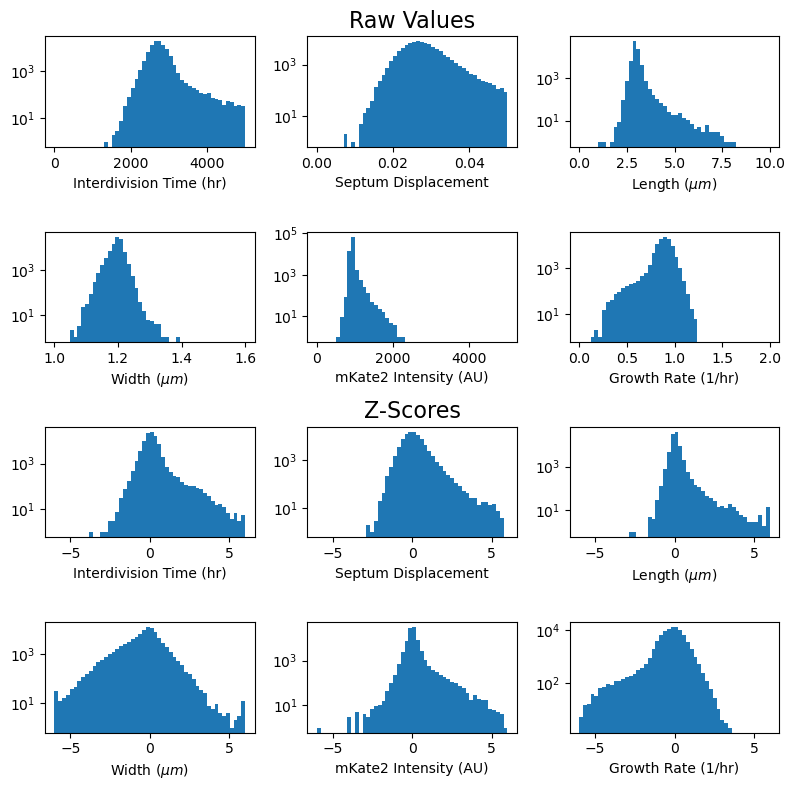

In [28]:
ncols=3
nrows=4

param_names = ["Interdivision Time (hr)","Septum Displacement",\
              r"Length ($ \mu m $)",r"Width ($ \mu m $)",\
              "mKate2 Intensity (AU)","Growth Rate (1/hr)"]
param_ranges = [(0,5000),(0,0.05),(0.,10.),\
               (1.,1.6),(0,5000),(0,2)]

fig = plt.figure(figsize=(8,8))
for i,param in enumerate(params_to_transform_kernel_reg):
    working_row = i//ncols
    param_name = param_names[i]
    param_range = param_ranges[i]
    param_transformed = param + ": Transformed: z score"
    vals = kernel_output_yj_df_sampled[param].values
    transformed_vals = kernel_output_yj_df_sampled[param_transformed].values
    
    plt.subplot(nrows,ncols,i+1)
    if i == 1:
        plt.title("Raw Values",fontsize=16)
    plt.hist(vals,bins=50,range=param_range,log=True)
    plt.xlabel(param_name)
    plt.subplot(nrows,ncols,i+1+(2*ncols))
    if i == 1:
        plt.title("Z-Scores",fontsize=16)
    plt.hist(transformed_vals,bins=50,range=(-6,6),log=True)
    plt.xlabel(param_name)
plt.tight_layout()
plt.savefig(HEADPATH+"/2025-08-11_Timeseries_Zscore_Transformation.png",dpi=300)

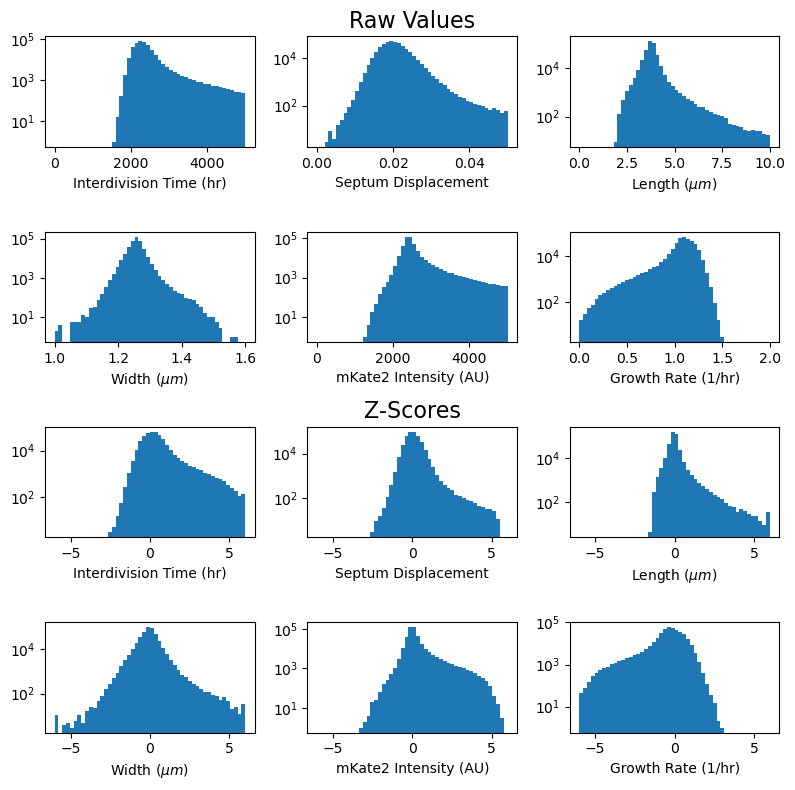

In [ ]:
# ncols=3
# nrows=4

# param_names = ["Interdivision Time (hr)","Septum Displacement",\
#               r"Length ($ \mu m $)",r"Width ($ \mu m $)",\
#               "mKate2 Intensity (AU)","Growth Rate (1/hr)"]
# param_ranges = [(0,5000),(0,0.05),(0.,10.),\
#                (1.,1.6),(0,5000),(0,2)]

# fig = plt.figure(figsize=(8,8))
# for i,param in enumerate(params_to_transform_kernel_reg):
#     working_row = i//ncols
#     param_name = param_names[i]
#     param_range = param_ranges[i]
#     param_transformed = param + ": Transformed: z score"
#     vals = kernel_output_yj_df_sampled[param].values
#     transformed_vals = kernel_output_yj_df_sampled[param_transformed].values
    
#     plt.subplot(nrows,ncols,i+1)
#     if i == 1:
#         plt.title("Raw Values",fontsize=16)
#     plt.hist(vals,bins=50,range=param_range,log=True)
#     plt.xlabel(param_name)
#     plt.subplot(nrows,ncols,i+1+(2*ncols))
#     if i == 1:
#         plt.title("Z-Scores",fontsize=16)
#     plt.hist(transformed_vals,bins=50,range=(-6,6),log=True)
#     plt.xlabel(param_name)
# plt.tight_layout()
# plt.savefig("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-21_Timeseries_Zscore_Transformation.png",dpi=300)

#### Merge Timeseries dfs

In [29]:
trenchid_label="Multi-Experiment Phenotype Trenchid"
kernel_score_params = [param + ": Transformed: z score" for param in params_to_transform_kernel_reg]
all_kernel_reg_columns = all_traced_params + kernel_score_params

kernel_output_yj_df_unexploded = kernel_output_yj_df.groupby(trenchid_label).apply(lambda x: pd.DataFrame({column: [x[column].tolist()] for column in x.columns}))
kernel_output_yj_df_unexploded = kernel_output_yj_df_unexploded[all_kernel_reg_columns]
kernel_output_yj_df_unexploded = kernel_output_yj_df_unexploded.persist()
wait(kernel_output_yj_df_unexploded);

cell_cycle_out = cell_cycle_df.groupby(trenchid_label).apply(lambda x: x.iloc[0])
cell_cycle_out = cell_cycle_out[['Global CellID', 'File Parquet Index', 'fov', 'row', 'trench',
       'initial timepoints', 'File Index', 'File Trench Index', 'CellID',
       'Trench Score', 'Mother CellID', 'Daughter CellID 1',
       'Daughter CellID 2', 'Sister CellID', 'Centroid X', 'Centroid Y',
       'Kymograph File Parquet Index', 'Kymograph FOV Parquet Index',
       'FOV Parquet Index', 'Experiment #', 'phenotype trenchid']]
cell_cycle_out = cell_cycle_out.persist()
wait(cell_cycle_out);

kernel_output_yj_df_unexploded = kernel_output_yj_df_unexploded.reset_index().set_index("Multi-Experiment Phenotype Trenchid", sorted=True)
kernel_output_yj_df_unexploded = kernel_output_yj_df_unexploded.drop("level_1",axis=1).persist()
wait(kernel_output_yj_df_unexploded);

timeseries_merged_dd = kernel_output_yj_df_unexploded.join(cell_cycle_out,on="Multi-Experiment Phenotype Trenchid")

/tmp/ipykernel_2954693/3964713271.py:5: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  kernel_output_yj_df_unexploded = kernel_output_yj_df.groupby(trenchid_label).apply(lambda x: pd.DataFrame({column: [x[column].tolist()] for column in x.columns}))
/tmp/ipykernel_2954693/3964713271.py:10: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  cell_cycle_out = cell_cycle_df.groupby(trenchid_label).apply(lambda x: x.iloc[0])


In [ ]:
# cell_cycle_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/', engine="pyarrow",calculate_divisions=True)
# timepoints_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Observations_Merged/', engine="pyarrow",calculate_divisions=True)
# growth_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Growth_Observations_Merged/', engine="pyarrow",calculate_divisions=True)

HEADPATH+PREFIX+'Final_Barcodes_df_Merged/'
final_output_df_barcodes = dd.read_parquet(HEADPATH+PREFIX+'Final_Barcodes_df_Merged/',engine="pyarrow",calculate_divisions=True)
final_output_df_barcodes.columns

Index(['FOV Parquet Index', 'phenotype trenchid', 'fov', 'row', 'trench',
       'timepoints', 'time (s)', 'lane orientation', 'y (local)', 'x (local)',
       'y (global)', 'x (global)', 'Global Row', 'File Index',
       'File Trench Index', 'File Parquet Index', 'Trenchid Timepoint Index',
       'timepoints_pre_shift', 'time (s)_pre_shift', 'index', 'trenchid',
       'Barcode', 'consensus', 'reference', 'alignmentstart', 'cigar',
       'subsample', 'barcode depth', 'closest_match', 'aligned_cons',
       'split_ref', 'split_align', 'hamm_ref', 'UMI', 'sgRNA',
       'Closest Hamming Distance', 'opLAG1_id', 'locus_tag', 'offset', 'Gene',
       'sgRNA Sequence', 'Target Sequence', 'Category', 'Predicted_Efficacy',
       'TargetID', 'barcode', 'barcodeid', 'Experiment #'],
      dtype='object')

#### Average over trenches for sgRNA-wise Timeseries

In [33]:
# COLS_TO_KEEP_BARCODE_DF = ['oDEPool7_id','Barcode','sgRNA','Closest Hamming Distance', 'EcoWG1_id', 'Gene', 'N Mismatch', 'Category', 'TargetID', 'barcodeid']
COLS_TO_KEEP_BARCODE_DF = ['opLAG1_id', 'Barcode', 'sgRNA', 'Closest Hamming Distance', 'locus_tag','Gene', 'sgRNA Sequence', 'Target Sequence', 'TargetID', 'barcode', 'barcodeid', 'Category', 'Predicted_Efficacy']

final_output_df_barcodes = dd.read_parquet(HEADPATH+PREFIX+'Final_Barcodes_df_Merged/',engine="pyarrow",calculate_divisions=True)
final_output_df_barcodes = final_output_df_barcodes.groupby(trenchid_label,sort=False).apply(lambda x: x.iloc[0]).persist()
wait(final_output_df_barcodes);

final_output_df_barcodes = final_output_df_barcodes.reset_index().set_index("opLAG1_id",drop=True)
final_output_df_barcodes = final_output_df_barcodes.reset_index().set_index(trenchid_label).persist()
wait(final_output_df_barcodes);
timeseries_merged_dd = timeseries_merged_dd.merge(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner',left_index=True,right_index=True).persist()

n_obs = timeseries_merged_dd.groupby("opLAG1_id",sort=False).apply(lambda x: len(x.index.unique()), meta=int).compute()
n_obs = pd.DataFrame(n_obs).rename({0:"N Observations"}, axis=1).sort_index()
timeseries_merged_dd = timeseries_merged_dd.merge(n_obs,on="opLAG1_id",how='inner',right_index=True)

feature_vector_series = timeseries_merged_dd.apply(lambda x: [eval(item) for item in x[kernel_score_params].tolist()], axis=1, meta=str)
timeseries_merged_dd["Feature Vector"] = feature_vector_series

timeseries_merged_dd_nan_filtered = timeseries_merged_dd[~timeseries_merged_dd["Feature Vector"].apply(lambda x: np.any(np.isnan(eval(x))),meta=("No NaN",bool))]

/tmp/ipykernel_2954693/209605863.py:5: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  final_output_df_barcodes = final_output_df_barcodes.groupby(trenchid_label,sort=False).apply(lambda x: x.iloc[0]).persist()
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be

#### Aggregate over timeseries

In [ ]:
HEADPATH+"/2025-08-11_sgRNA_Timeseries_df.pkl"

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed//2025-08-11_sgRNA_Timeseries_df.pkl'

In [36]:
## params
vectors_to_aggregate = ['Feature Vector'] + all_kernel_reg_columns

timeseries_merged_dd_nan_filtered_sgRNA_sorted = timeseries_merged_dd_nan_filtered.set_index("opLAG1_id").persist()
timeseries_merged_dd_nan_filtered_sgRNA_sorted_groupby = timeseries_merged_dd_nan_filtered_sgRNA_sorted.groupby(["opLAG1_id"])
    
sgRNA_df_merged = timeseries_merged_dd_nan_filtered_sgRNA_sorted_groupby.apply(lambda x: x.iloc[0]).persist()
sgRNA_df_merged = sgRNA_df_merged.compute()

for vector in vectors_to_aggregate:
    print(vector)
    mean_vectors = timeseries_merged_dd_nan_filtered_sgRNA_sorted_groupby.apply(lambda x: \
            np.mean(np.array([eval(item) for item in x[vector].tolist()]), axis=0).tolist(), meta=(None,object)).compute()
    mean_vectors = mean_vectors.apply(lambda x: np.array(eval(x)))
    sgRNA_df_merged[vector] = mean_vectors
    
    sem_vectors = timeseries_merged_dd_nan_filtered_sgRNA_sorted_groupby.apply(lambda x: \
            agg_sem(x,vector), meta=(None,object)).compute()
    sem_vectors = sem_vectors.apply(lambda x: unpack_sem(x))
    sgRNA_df_merged["SEM: " + vector] = sem_vectors

sgRNA_df_merged.to_pickle(HEADPATH+"/2025-08-11_sgRNA_Timeseries_df.pkl")

/tmp/ipykernel_2954693/2453488846.py:7: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  sgRNA_df_merged = timeseries_merged_dd_nan_filtered_sgRNA_sorted_groupby.apply(lambda x: x.iloc[0]).persist()


Feature Vector
Kernel Trace: Birth: Length
Kernel Trace: Division: Length
Kernel Trace: Delta: Length
Kernel Trace: Birth: Width
Kernel Trace: Division: Width
Kernel Trace: Delta: Width
Kernel Trace: Birth: Volume
Kernel Trace: Division: Volume
Kernel Trace: Delta: Volume
Kernel Trace: Final timepoints
Kernel Trace: Delta Timepoints
Kernel Trace: Final time (s)
Kernel Trace: Delta time (s)
Kernel Trace: Septum Displacement
Kernel Trace: Septum Displacement Length Normalized
Kernel Trace: area
Kernel Trace: Length
Kernel Trace: Width
Kernel Trace: Volume
Kernel Trace: mCherry mean_intensity
Kernel Trace: Instantaneous Growth Rate: Volume
Kernel Trace: Instantaneous Growth Rate: Length
Kernel Trace: Delta time (s): Transformed: z score
Kernel Trace: Septum Displacement Length Normalized: Transformed: z score
Kernel Trace: Length: Transformed: z score
Kernel Trace: Width: Transformed: z score
Kernel Trace: mCherry mean_intensity: Transformed: z score
Kernel Trace: Instantaneous Growth Rat

### Jackknife Sampling for Cluster Stability
- Leave one out for 10 partitions of the data
- Compute the mean with the remainder
- Later, perform clustering on these jackknife samples

In [37]:
HEADPATH + '/jackknife_df.pkl'
HEADPATH + 'jackknife_df_temp.pkl'

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/jackknife_df_temp.pkl'

In [ ]:
jackknife_df_path = HEADPATH + '/jackknife_df.pkl'
jackknife_df_temp_path = HEADPATH + '/jackknife_df_temp.pkl'

sgrnaid_series = timeseries_merged_dd_nan_filtered["opLAG1_id"].compute()
feature_vector_series = timeseries_merged_dd_nan_filtered["Feature Vector"].compute()
feature_vector_series = feature_vector_series.apply(lambda x: np.array(eval(x)))
jackknife_df = pd.concat([sgrnaid_series,feature_vector_series], axis=1)
jackknife_df.to_pickle(jackknife_df_temp_path)

In [41]:
jackknife_ttl = 10

jackknife_dd = []
for jackknife_i in range(jackknife_ttl):
    delayed_jackknife = dask.delayed(get_jackknife_mean)(jackknife_df_temp_path,jackknife_i,jackknife_ttl)
    jackknife_dd.append(delayed_jackknife)
jackknife_df = dd.from_delayed(jackknife_dd).compute()
jackknife_df["Feature Vector"] = jackknife_df["Feature Vector"].apply(lambda x: np.array(eval(x)))
jackknife_df["SEM: Feature Vector"] = jackknife_df["SEM: Feature Vector"].apply(lambda x: unpack_sem_jackknife(x))
jackknife_df = jackknife_df.reset_index().set_index(["Jackknife","opLAG1_id"])
jackknife_df.to_pickle(jackknife_df_path)

In [42]:
dask_controller.daskclient.cancel(cell_cycle_df)
dask_controller.daskclient.cancel(kernel_output_yj_df)
dask_controller.daskclient.cancel(timeseries_merged_dd)
dask_controller.daskclient.cancel(final_output_df_barcodes)
dask_controller.reset_worker_memory()

Done.


#### Get Steady State Measurements (for timeseries)
- Note corespond to the values for the timesries representation after 5 hours of induction
- These are not the values typically plotted

In [ ]:
# cell_cycle_df = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Cell_Cycle_Merged/", engine="pyarrow",calculate_divisions=True)
# timepoints_df = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Observations_Merged/", engine="pyarrow",calculate_divisions=True)
# growth_df = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Growth_Observations_Merged/", engine="pyarrow",calculate_divisions=True)
# HEADPATH+PREFIX+'Final_Barcodes_df_Merged/'

cell_cycle_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Cell_Cycle_Merged/', engine="pyarrow",calculate_divisions=True)
timepoints_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Observations_Merged/', engine="pyarrow",calculate_divisions=True)
growth_df = dd.read_parquet(HEADPATH+PREFIX+'Lineage_Growth_Observations_Merged/', engine="pyarrow",calculate_divisions=True)


cell_cycle_params = ['Birth: Length', 'Division: Length',
   'Delta: Length', 'Birth: Width',
   'Division: Width', 'Delta: Width',
   'Birth: Volume', 'Division: Volume', 'Delta: Volume',
   'Final timepoints', 'Delta Timepoints', 'Final time (s)',
   'Delta time (s)','Septum Displacement','Septum Displacement Length Normalized']
timepoints_params = ['area','Length', 'Width', 'Volume','mCherry mean_intensity']
growth_params = ['Instantaneous Growth Rate: Volume', 'Instantaneous Growth Rate: Length']
all_traced_params = cell_cycle_params + timepoints_params + growth_params

#### Use Steady State Time to Filter

In [44]:
steady_state_time = 9*3600 #7 hours
induction_time = 4*3600 # 2 hours

trenchid_label="Multi-Experiment Phenotype Trenchid"

cell_cycle_df_ss = cell_cycle_df[cell_cycle_df["Initial time (s)"]>=steady_state_time]
cell_cycle_df_pre = cell_cycle_df[cell_cycle_df["Final time (s)"]<=induction_time]

timepoints_df_ss = timepoints_df[timepoints_df["Observation time (s)"]>=steady_state_time]
timepoints_df_pre = timepoints_df[timepoints_df["Observation time (s)"]<=induction_time]

growth_df_ss = growth_df[growth_df["Measurement time (s)"]>=steady_state_time]
growth_df_pre = growth_df[growth_df["Measurement time (s)"]<=induction_time]

#### Add sgRNA info for real data and save as checkpoint

In [55]:
HEADPATH
PREFIX_OUTPUT = '2025-08-11_lLAG8_'
SUFFIX_STEADY_STATE = '_Timeseries_Steady_State/'
SUFFIX_PREINDUCTION = '_Timeseries_Preinduction/'

HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_PREINDUCTION

HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_PREINDUCTION

HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_PREINDUCTION

'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/2025-08-11_lLAG8_Lineage_Growth_Timeseries_Preinduction/'

In [56]:
COLS_TO_KEEP_BARCODE_DF = ['opLAG1_id', 'Barcode', 'sgRNA', 'Closest Hamming Distance', 'locus_tag','Gene', 'sgRNA Sequence', 'Target Sequence', 'TargetID', 'barcode', 'barcodeid', 'Category', 'Predicted_Efficacy']

final_output_df_barcodes = dd.read_parquet(HEADPATH+PREFIX+'Final_Barcodes_df_Merged/',engine="pyarrow",calculate_divisions=True)
final_output_df_barcodes = final_output_df_barcodes.groupby(trenchid_label,sort=False).apply(lambda x: x.iloc[0]).persist()
wait(final_output_df_barcodes);

final_output_df_barcodes = final_output_df_barcodes.reset_index().set_index("opLAG1_id",drop=True)
final_output_df_barcodes = final_output_df_barcodes.reset_index().set_index(trenchid_label).persist()
wait(final_output_df_barcodes);

cell_cycle_df_ss = cell_cycle_df_ss.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
cell_cycle_df_pre = cell_cycle_df_pre.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
n_obs = cell_cycle_df_ss.groupby("opLAG1_id",sort=False).apply(lambda x: len(x.index.unique()), meta=int).compute()
n_obs = pd.DataFrame(n_obs).rename({0:"N Observations"}, axis=1).sort_index()
cell_cycle_df_ss = cell_cycle_df_ss.merge(n_obs,on="opLAG1_id",how='inner')
cell_cycle_df_pre = cell_cycle_df_pre.merge(n_obs,on="opLAG1_id",how='inner')
cell_cycle_df_ss.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_STEADY_STATE, engine="pyarrow", overwrite=True)
cell_cycle_df_pre.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_PREINDUCTION, engine="pyarrow", overwrite=True)
print("Cell Cycle Done.")

timepoints_df_ss = timepoints_df_ss.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
timepoints_df_pre = timepoints_df_pre.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
n_obs = timepoints_df_ss.groupby("opLAG1_id",sort=False).apply(lambda x: len(x.index.unique()), meta=int).compute()
n_obs = pd.DataFrame(n_obs).rename({0:"N Observations"}, axis=1).sort_index()
timepoints_df_ss = timepoints_df_ss.merge(n_obs,on="opLAG1_id",how='inner')
timepoints_df_pre = timepoints_df_pre.merge(n_obs,on="opLAG1_id",how='inner')
timepoints_df_ss.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_STEADY_STATE, engine="pyarrow", overwrite=True)
timepoints_df_pre.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_PREINDUCTION, engine="pyarrow", overwrite=True)
print("Timepoints Done.")

growth_df_ss = growth_df_ss.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
growth_df_pre = growth_df_pre.join(final_output_df_barcodes[COLS_TO_KEEP_BARCODE_DF],how='inner')
n_obs = growth_df_ss.groupby("opLAG1_id",sort=False).apply(lambda x: len(x.index.unique()), meta=int).compute()
n_obs = pd.DataFrame(n_obs).rename({0:"N Observations"}, axis=1).sort_index()
growth_df_ss = growth_df_ss.merge(n_obs,on="opLAG1_id",how='inner')
growth_df_pre = growth_df_pre.merge(n_obs,on="opLAG1_id",how='inner')
growth_df_ss.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_STEADY_STATE, engine="pyarrow", overwrite=True)
growth_df_pre.to_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_PREINDUCTION, engine="pyarrow", overwrite=True)
print("Growth Done.")
dask_controller.reset_worker_memory()

/tmp/ipykernel_2954693/1912585530.py:4: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  final_output_df_barcodes = final_output_df_barcodes.groupby(trenchid_label,sort=False).apply(lambda x: x.iloc[0]).persist()
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(


Cell Cycle Done.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(


Timepoints Done.


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/dataframe/core.py:7234: FutureWarning: Meta is not valid, `map_partitions` and `map_overlap` expects output to be a pandas object. Try passing a pandas object as meta or a dict or tuple representing the (name, dtype) of the columns. In the future the meta you passed will not work.
  warnings.warn(


Growth Done.
Done.


### Calculate Means, Variances and CVs of Measured Quantities

In [ ]:
HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_PREINDUCTION

HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_PREINDUCTION

HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_STEADY_STATE
HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_PREINDUCTION

In [ ]:
HEADPATH + PREFIX_OUTPUT+"Lineage_Cell_Cycle_Timeseries_Preinduction_MeanCV.pkl"


'/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/2025-08-11_lLAG8_Lineage_Cell_Cycle_Timeseries_Preinduction_MeanCV.pkl'

In [61]:
# cell_cycle_df_ss = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Cell_Cycle_Timeseries_Steady_State",engine="pyarrow",calculate_divisions=True)
# cell_cycle_df_pre = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Cell_Cycle_Timeseries_Preinduction",engine="pyarrow",calculate_divisions=True)

# timepoints_df_ss = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Timepoints_Timeseries_Steady_State",engine="pyarrow",calculate_divisions=True)
# timepoints_df_pre = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Timepoints_Timeseries_Preinduction",engine="pyarrow",calculate_divisions=True)

# growth_df_ss = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Growth_Timeseries_Steady_State",engine="pyarrow",calculate_divisions=True)
# growth_df_pre = dd.read_parquet("/home/de64/scratch/de64/sync_folder/2023-01-18_lDE20_Merged_Analysis/2023-01-18_lDE20_Lineage_Growth_Timeseries_Preinduction",engine="pyarrow",calculate_divisions=True)

cell_cycle_df_ss = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_STEADY_STATE,engine="pyarrow",calculate_divisions=True)
cell_cycle_df_pre = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Cell_Cycle' + SUFFIX_PREINDUCTION,engine="pyarrow",calculate_divisions=True)

timepoints_df_ss = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_STEADY_STATE,engine="pyarrow",calculate_divisions=True)
timepoints_df_pre = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Timepoints' + SUFFIX_PREINDUCTION,engine="pyarrow",calculate_divisions=True)

growth_df_ss = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_STEADY_STATE,engine="pyarrow",calculate_divisions=True)
growth_df_pre = dd.read_parquet(HEADPATH + PREFIX_OUTPUT + 'Lineage_Growth' + SUFFIX_PREINDUCTION,engine="pyarrow",calculate_divisions=True)

# COLS_TO_KEEP_BARCODE_DF = ['opLAG1_id', 'Barcode', 'sgRNA', 'Closest Hamming Distance', 'locus_tag','Gene', 'sgRNA Sequence', 'Target Sequence', 'TargetID', 'barcode', 'barcodeid', 'Category', 'Predicted_Efficacy']
COLS_TO_KEEP_BARCODE_DF_FILTERED = ['sgRNA', 'locus_tag', 'Gene', 'Predicted_Efficacy',  'Category', 'TargetID', 'N Observations']

# final_columns = ['sgRNA','EcoWG1_id', 'Gene', 'N Mismatch', 'Category', 'TargetID', 'N Observations']
final_columns  = COLS_TO_KEEP_BARCODE_DF_FILTERED

cell_cycle_df_ss_mean_cv = get_mean_var_and_cv(cell_cycle_df_ss,final_columns,cell_cycle_params,sgrna_key='opLAG1_id')
timepoints_df_ss_mean_cv = get_mean_var_and_cv(timepoints_df_ss,final_columns,timepoints_params,sgrna_key='opLAG1_id')
growth_df_ss_mean_cv = get_mean_var_and_cv(growth_df_ss,final_columns,growth_params,sgrna_key='opLAG1_id')

timepoints_df_ss_mean_cv = timepoints_df_ss_mean_cv[["Mean: " + item for item in timepoints_params] + ["Variance: " + item for item in timepoints_params] + ["CV: " + item for item in timepoints_params]]
growth_df_ss_mean_cv = growth_df_ss_mean_cv[["Mean: " + item for item in growth_params] + ["Variance: " + item for item in growth_params] + ["CV: " + item for item in growth_params]]

output_ss_meancv = pd.concat([cell_cycle_df_ss_mean_cv,timepoints_df_ss_mean_cv,growth_df_ss_mean_cv],axis=1).sort_index()
output_ss_meancv.to_pickle(HEADPATH + PREFIX_OUTPUT+"Lineage_Cell_Cycle_Timeseries_Steady_State_MeanCV.pkl")

del cell_cycle_df_ss_mean_cv
del timepoints_df_ss_mean_cv
del growth_df_ss_mean_cv
del output_ss_meancv

cell_cycle_df_pre_mean_cv = get_mean_var_and_cv(cell_cycle_df_pre,final_columns,cell_cycle_params,sgrna_key='opLAG1_id')
timepoints_df_pre_mean_cv = get_mean_var_and_cv(timepoints_df_pre,final_columns,timepoints_params,sgrna_key='opLAG1_id')
growth_df_pre_mean_cv = get_mean_var_and_cv(growth_df_pre,final_columns,growth_params,sgrna_key='opLAG1_id')

timepoints_df_pre_mean_cv = timepoints_df_pre_mean_cv[["Mean: " + item for item in timepoints_params] + ["Variance: " + item for item in timepoints_params] + \
["CV: " + item for item in timepoints_params] + ["SEM: " + item for item in timepoints_params]]
growth_df_pre_mean_cv = growth_df_pre_mean_cv[["Mean: " + item for item in growth_params] + ["Variance: " + item for item in growth_params] + \
["CV: " + item for item in growth_params] + ["SEM: " + item for item in growth_params]]

output_pre_meancv = pd.concat([cell_cycle_df_pre_mean_cv,timepoints_df_pre_mean_cv,growth_df_pre_mean_cv],axis=1).sort_index()
output_pre_meancv.to_pickle(HEADPATH + PREFIX_OUTPUT+"Lineage_Cell_Cycle_Timeseries_Preinduction_MeanCV.pkl");

del cell_cycle_df_pre_mean_cv
del timepoints_df_pre_mean_cv
del growth_df_pre_mean_cv
del output_pre_meancv

/tmp/ipykernel_2954693/893425814.py:144: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  mean_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: np.mean(x,axis=0)).compute()
/tmp/ipykernel_2954693/893425814.py:145: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  std_df = sgrna_groupby[columns_to_apply_aggregation].apply(lambda x: np.std(x,axis=0,ddof=1)).compute()
/tmp/ipykernel_2954693/893425814.py:147: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is

In [76]:
dask_controller.shutdown()

Done.


2025-08-11 15:49:38,303 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [66]:
COLS_TO_KEEP_BARCODE_DF_FILTERED = ['opLAG1_id', 'sgRNA', 'locus_tag', 'Gene', 'Predicted_Efficacy',  'Category', 'TargetID']
dd_bar = dd.read_parquet(HEADPATH+PREFIX+'Final_Barcodes_df_Merged/', columns = COLS_TO_KEEP_BARCODE_DF_FILTERED)

In [67]:
df_bar = dd_bar.groupby(dd_bar.index).first().compute()

In [70]:
df_bar = df_bar.groupby('opLAG1_id').first()

In [64]:
df_kernel = pd.read_pickle(HEADPATH+"/2025-08-11_sgRNA_Timeseries_df.pkl")

In [83]:
df_kernel.columns

Index(['Kernel Trace: Birth: Length', 'Kernel Trace: Division: Length',
       'Kernel Trace: Delta: Length', 'Kernel Trace: Birth: Width',
       'Kernel Trace: Division: Width', 'Kernel Trace: Delta: Width',
       'Kernel Trace: Birth: Volume', 'Kernel Trace: Division: Volume',
       'Kernel Trace: Delta: Volume', 'Kernel Trace: Final timepoints',
       'Kernel Trace: Delta Timepoints', 'Kernel Trace: Final time (s)',
       'Kernel Trace: Delta time (s)', 'Kernel Trace: Septum Displacement',
       'Kernel Trace: Septum Displacement Length Normalized',
       'Kernel Trace: area', 'Kernel Trace: Length', 'Kernel Trace: Width',
       'Kernel Trace: Volume', 'Kernel Trace: mCherry mean_intensity',
       'Kernel Trace: Instantaneous Growth Rate: Volume',
       'Kernel Trace: Instantaneous Growth Rate: Length',
       'Kernel Trace: Delta time (s): Transformed: z score',
       'Kernel Trace: Septum Displacement Length Normalized: Transformed: z score',
       'Kernel Trace: Lengt

In [ ]:
df_subset = df_kernel[df_kernel['Category']=='control'].sample()

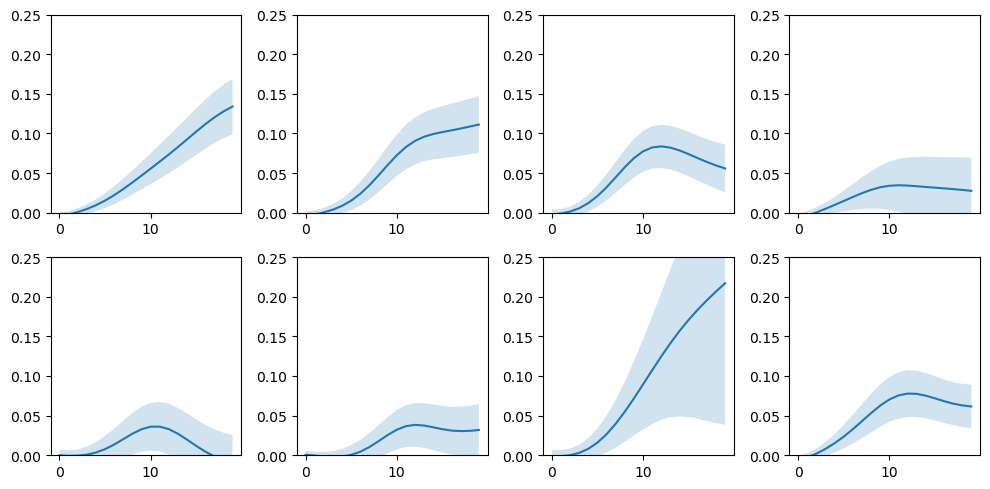

In [96]:
N_ROWS = 2
N_COLS = 4

df_subset = df_kernel[df_kernel['Category']=='control'].sample(N_ROWS*N_COLS, random_state=42)
column_name = 'Kernel Trace: Length: Transformed: z score'
column_name_sem = 'SEM: ' + column_name

fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(10, 5))
for i, (index, row) in enumerate(df_subset.iterrows()):
    if i >= N_ROWS * N_COLS:
        break
    ax = axs[i // N_COLS, i % N_COLS]
    kernel_trace = row[column_name]
    kernel_trace_sem = row[column_name_sem]
    
    timepoints = np.arange(len(kernel_trace))
    
    ax.plot(timepoints, kernel_trace, label='Kernel Trace')
    ax.fill_between(timepoints, kernel_trace - kernel_trace_sem, kernel_trace + kernel_trace_sem, alpha=0.2, label='SEM')
    
    ax.set_ylim((0,0.25))
    # ax.set_title(f"sgRNA: {row['sgRNA']}, Gene: {row['Gene']}")
    # ax.set_xlabel('Timepoints')
    # ax.set_ylabel('Transformed Length')
    # ax.legend()
plt.tight_layout()





In [100]:
df_kernel[df_kernel['Gene']=='rplM']

,Kernel Trace: Birth: Length,Kernel Trace: Division: Length,Kernel Trace: Delta: Length,Kernel Trace: Birth: Width,Kernel Trace: Division: Width,Kernel Trace: Delta: Width,Kernel Trace: Birth: Volume,Kernel Trace: Division: Volume,Kernel Trace: Delta: Volume,Kernel Trace: Final timepoints,...,SEM: Kernel Trace: Volume,SEM: Kernel Trace: mCherry mean_intensity,SEM: Kernel Trace: Instantaneous Growth Rate: Volume,SEM: Kernel Trace: Instantaneous Growth Rate: Length,SEM: Kernel Trace: Delta time (s): Transformed: z score,SEM: Kernel Trace: Septum Displacement Length Normalized: Transformed: z score,SEM: Kernel Trace: Length: Transformed: z score,SEM: Kernel Trace: Width: Transformed: z score,SEM: Kernel Trace: mCherry mean_intensity: Transformed: z score,SEM: Kernel Trace: Instantaneous Growth Rate: Volume: Transformed: z score
opLAG1_id,,,,,,,,,,,,,,,,,,,,,
1233.0,"[2.1857893959960397, 2.185618955822739, 2.1859...","[4.276604052594496, 4.280346948405314, 4.28478...","[2.090814656598456, 2.0947279925825746, 2.0988...","[1.205534373873127, 1.205283099969694, 1.20503...","[1.194371415201226, 1.1936043597011983, 1.1927...","[-0.011162958671901169, -0.011678740268494971,...","[2.1745015664029768, 2.173113566214555, 2.1722...","[4.176950132562113, 4.179388317970896, 4.18231...","[2.0024485661591367, 2.0062747517563415, 2.010...","[20.492342780997795, 21.381255235298266, 22.45...",...,"[0.005764610553709591, 0.005010988656697847, 0...","[0.730729907477089, 0.7463763351460999, 0.9141...","[0.013057176771847055, 0.012252575956452573, 0...","[0.00837680885493523, 0.007996806157099984, 0....","[0.06447937773998023, 0.061217694570223295, 0....","[0.10245838598192955, 0.0960662851836732, 0.08...","[0.00602964711769324, 0.0051525367956864855, 0...","[0.03966505236865597, 0.03671031544409034, 0.0...","[0.007948879971107619, 0.008139367035257201, 0...","[0.13127423327799367, 0.12323993179364304, 0.1..."
1234.0,"[2.193958535508408, 2.1940313397851474, 2.1947...","[4.2947770757007175, 4.297836041752024, 4.3015...","[2.100818540192309, 2.1038047019668786, 2.1067...","[1.2063603081411471, 1.2050927811285554, 1.203...","[1.1904789721364695, 1.1902861187324743, 1.190...","[-0.01588133600467717, -0.014806662396080786, ...","[2.175292290906076, 2.1736800818951396, 2.1723...","[4.194656813422278, 4.1957396371227205, 4.1970...","[2.019364522516203, 2.0220595552275804, 2.0247...","[19.94547768675006, 20.851139463997068, 21.944...",...,"[0.004703166610498471, 0.004320744798704228, 0...","[0.7618616293408443, 0.6444649678353827, 0.692...","[0.01129739364231368, 0.010746166066211623, 0....","[0.006714574470609057, 0.006608412086587914, 0...","[0.05809630937077705, 0.05586844923889603, 0.0...","[0.07919667810994385, 0.0726730711632471, 0.06...","[0.005188214760609194, 0.004771724787496323, 0...","[0.03515815584911096, 0.028627376710505182, 0....","[0.008258191157799138, 0.006948906908584603, 0...","[0.11347286162076087, 0.10778051471640132, 0.1..."
1235.0,"[2.182507004999419, 2.1829179382856347, 2.1838...","[4.286273328917634, 4.290350956727699, 4.29498...","[2.1037663239182143, 2.1074330184420638, 2.111...","[1.2045970396174919, 1.2043324862847202, 1.204...","[1.1924285203369411, 1.1919340568752843, 1.191...","[-0.012168519280550126, -0.012398429409435769,...","[2.168537286087094, 2.167694192926516, 2.16724...","[4.1970949164850095, 4.198910760452957, 4.2010...","[2.028557630397915, 2.0312165675264393, 2.0337...","[19.886079110486776, 20.8145499066515, 21.9425...",...,"[0.0037801001228620853, 0.0034232925955427233,...","[0.4485712417017697, 0.40697849699341043, 0.47...","[0.007217269164416701, 0.006860976489865866, 0...","[0.0051335182595719925, 0.0049535619951822235,...","[0.0396269950300213, 0.037629584360145525, 0.0...","[0.0650709446195942, 0.06178318625541709, 0.05...","[0.004069854984094996, 0.0038983523276918015, ...","[0.029846615486188638, 0.02612601190151811, 0....","[0.004854053280069943, 0.004406934285199679, 0...","[0.0725088004738226, 0.0688246

In [128]:
df_subset.columns

Index(['Kernel Trace: Birth: Length', 'Kernel Trace: Division: Length',
       'Kernel Trace: Delta: Length', 'Kernel Trace: Birth: Width',
       'Kernel Trace: Division: Width', 'Kernel Trace: Delta: Width',
       'Kernel Trace: Birth: Volume', 'Kernel Trace: Division: Volume',
       'Kernel Trace: Delta: Volume', 'Kernel Trace: Final timepoints',
       'Kernel Trace: Delta Timepoints', 'Kernel Trace: Final time (s)',
       'Kernel Trace: Delta time (s)', 'Kernel Trace: Septum Displacement',
       'Kernel Trace: Septum Displacement Length Normalized',
       'Kernel Trace: area', 'Kernel Trace: Length', 'Kernel Trace: Width',
       'Kernel Trace: Volume', 'Kernel Trace: mCherry mean_intensity',
       'Kernel Trace: Instantaneous Growth Rate: Volume',
       'Kernel Trace: Instantaneous Growth Rate: Length',
       'Kernel Trace: Delta time (s): Transformed: z score',
       'Kernel Trace: Septum Displacement Length Normalized: Transformed: z score',
       'Kernel Trace: Lengt

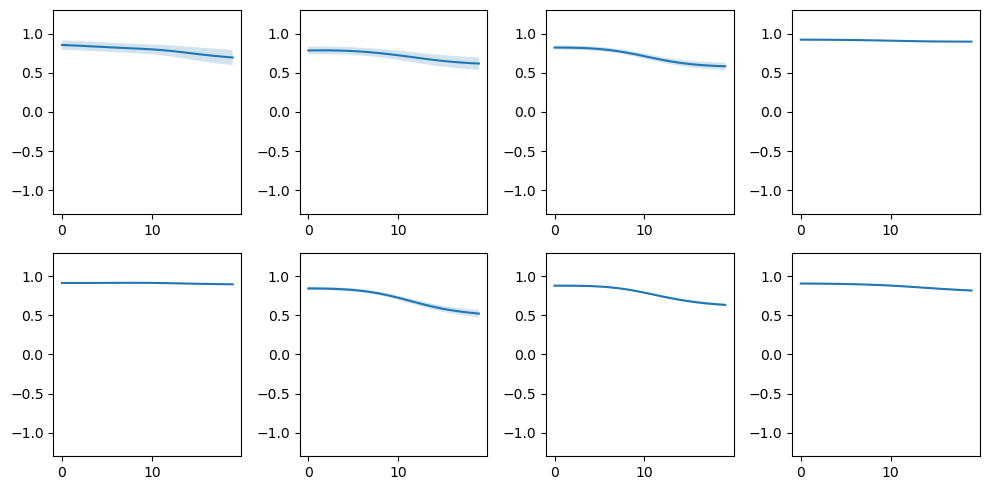

In [163]:
N_ROWS = 2
N_COLS = 4

# df_subset = df_kernel[df_kernel['Category']=='control'].sample(N_ROWS*N_COLS, random_state=42)
df_subset = df_kernel[df_kernel['Gene']=='pyk'].sample(N_ROWS*N_COLS, random_state=None)

column_name = 'Kernel Trace: Instantaneous Growth Rate: Volume'
# column_name = 'Kernel Trace: Length: Transformed: z score'
column_name_sem = 'SEM: ' + column_name

fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(10, 5))
for i, (index, row) in enumerate(df_subset.iterrows()):
    if i >= N_ROWS * N_COLS:
        break
    ax = axs[i // N_COLS, i % N_COLS]
    kernel_trace = row[column_name]
    kernel_trace_sem = row[column_name_sem]
    
    timepoints = np.arange(len(kernel_trace))
    
    ax.plot(timepoints, kernel_trace, label='Kernel Trace')
    ax.fill_between(timepoints, kernel_trace - kernel_trace_sem, kernel_trace + kernel_trace_sem, alpha=0.2, label='SEM')
    
    ax.set_ylim((-1.3,1.3))
    # ax.set_title(f"sgRNA: {row['sgRNA']}, Gene: {row['Gene']}")
    # ax.set_xlabel('Timepoints')
    # ax.set_ylabel('Transformed Length')
    # ax.legend()
plt.tight_layout()

In [ ]:
df_subset = df_kernel[df_kernel['Category']=='control'].sample(N_ROWS*N_COLS, random_state=42)


In [88]:
df_kernel.columns

Index(['Kernel Trace: Birth: Length', 'Kernel Trace: Division: Length',
       'Kernel Trace: Delta: Length', 'Kernel Trace: Birth: Width',
       'Kernel Trace: Division: Width', 'Kernel Trace: Delta: Width',
       'Kernel Trace: Birth: Volume', 'Kernel Trace: Division: Volume',
       'Kernel Trace: Delta: Volume', 'Kernel Trace: Final timepoints',
       'Kernel Trace: Delta Timepoints', 'Kernel Trace: Final time (s)',
       'Kernel Trace: Delta time (s)', 'Kernel Trace: Septum Displacement',
       'Kernel Trace: Septum Displacement Length Normalized',
       'Kernel Trace: area', 'Kernel Trace: Length', 'Kernel Trace: Width',
       'Kernel Trace: Volume', 'Kernel Trace: mCherry mean_intensity',
       'Kernel Trace: Instantaneous Growth Rate: Volume',
       'Kernel Trace: Instantaneous Growth Rate: Length',
       'Kernel Trace: Delta time (s): Transformed: z score',
       'Kernel Trace: Septum Displacement Length Normalized: Transformed: z score',
       'Kernel Trace: Lengt